# Giorno 1, pomeriggio: funzioni, errori, file e NumPy

Obiettivo del pomeriggio: uno script che apre una cartella di file prodotti dallo
strumento, estrae da ciascuno un valore e salva una tabella riassuntiva. Poi un primo grafico
per controllare a occhio che i dati siano sensati.

## 0. Cella di avvio

In [1]:
from pathlib import Path
import sys

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
print("Cartella dati:", DATI.resolve())

Cartella dati: /home/claude/corso_python_cnr/dati


---
## 1. Funzioni: dare un nome a un pezzo di lavoro

Stamattina avete calcolato una media con un ciclo. Se vi serve dieci volte, non la
riscrivete dieci volte: la mettete in una **funzione**.

```python
def nome(argomenti):
    """Docstring: una riga che dice cosa fa."""
    ...calcoli...
    return risultato
```

- `def` + nome + parentesi con gli argomenti (gli ingressi) + `:`
- il corpo è indentato
- `return` restituisce il risultato. Senza `return`, la funzione restituisce `None`.

In Excel è come definire una formula personalizzata. Le funzioni le usate già tutti i giorni:
`=MEDIA(B2:B9)` è una chiamata di funzione con un argomento.

In [2]:
def media(valori):
    """Media aritmetica di una lista di numeri."""
    return sum(valori) / len(valori)

correnti = [3.21, 3.35, 3.18, 3.30, 3.27, 3.19, 3.33]
m = media(correnti)
print(f"media = {m:.3f}")
print(media([1, 2, 3]))

media = 3.261
2.0


In [3]:
def dev_std(valori):
    """Deviazione standard campionaria (n-1)."""
    mu = media(valori)                       # una funzione può usarne un'altra
    somma_q = sum((x - mu) ** 2 for x in valori)
    return (somma_q / (len(valori) - 1)) ** 0.5

print(f"{media(correnti):.3f} ± {dev_std(correnti):.3f} µA")

3.261 ± 0.069 µA


### Argomenti con valore predefinito, e più valori di ritorno

In [4]:
def ug_L_a_nM(conc_ug_L, massa_molare=63.55):
    """Converte µg/L in nmol/L. Il default è il rame."""
    return conc_ug_L / massa_molare * 1000

print(ug_L_a_nM(25.4))                    # rame
print(ug_L_a_nM(25.4, massa_molare=207.2))  # piombo
print(ug_L_a_nM(massa_molare=112.4, conc_ug_L=1.5))   # per nome, in qualsiasi ordine

399.6852871754524
122.58687258687259
13.345195729537366


In [5]:
def statistiche(valori):
    """Restituisce (media, dev.std, n) come tupla."""
    return media(valori), dev_std(valori), len(valori)

mu, s, n = statistiche(correnti)           # spacchettamento
print(mu, s, n)

3.261428571428571 0.06890296835129127 7


> Una funzione con una docstring chiara e un piccolo test (`media([1, 2, 3])` deve dare
> `2.0`) è codice che potete verificare. Vi servirà anche per controllare codice scritto da
> altri, che siano colleghi o un assistente automatico.

### Esercizio 2.1: la vostra prima funzione (livello 2)

In una prova di recupero si aggiunge a un campione (qui senza analita) una quantità nota di
analita (*spike*) e si misura quanto se ne ritrova. Scrivete `recupero_percentuale(ritrovato, aggiunto)`
che restituisce il recupero in % (ritrovato / aggiunto × 100), con una docstring.
Testatela: `recupero_percentuale(48.2, 50)` deve dare `96.4`.

In [6]:
# ESERCIZIO 2.1 (livello 2)
# def recupero_percentuale(...):
#     """..."""
#     return ...
# print(recupero_percentuale(48.2, 50))
# --- SOLUZIONE ---
def recupero_percentuale(ritrovato, aggiunto):
    """Recupero di uno spike in percento: ritrovato / aggiunto × 100."""
    return ritrovato / aggiunto * 100

print(recupero_percentuale(48.2, 50))

96.4


---
## 2. Import e librerie

Python da solo sa fare poco. Il resto sta nelle **librerie**, che si caricano con
`import`. Queste quattro le userete ogni giorno, con questi alias (sono una convenzione
che seguono tutti, conviene non cambiarli):

In [7]:
import numpy as np                  # array e calcolo numerico
import pandas as pd                 # tabelle (da domani)
import matplotlib.pyplot as plt     # grafici
from pathlib import Path            # percorsi di file e cartelle

print(np.__version__, pd.__version__)

2.5.2 3.0.5


Le funzioni della libreria si chiamano con `libreria.funzione`: `np.mean`, `np.sqrt`,
`plt.subplots`. Per sapere cosa fa una funzione: `np.mean?` in una cella (o `Shift+Tab`
con il cursore sul nome). Non serve memorizzare, basta sapere dove consultare.

In [8]:
import math
print(math.sqrt(2), np.sqrt(2))
print(np.mean(correnti), np.std(correnti, ddof=1))   # ddof=1 -> campionaria (n-1), come sd() in R; il default di NumPy è n

1.4142135623730951 1.4142135623730951
3.261428571428571 0.06890296835129128


---
## 3. Leggere un traceback

Saper leggere un messaggio di errore è ciò che vi permette di cavarvela da soli. Il messaggio
descrive cosa è andato storto, e va letto **dal basso**.

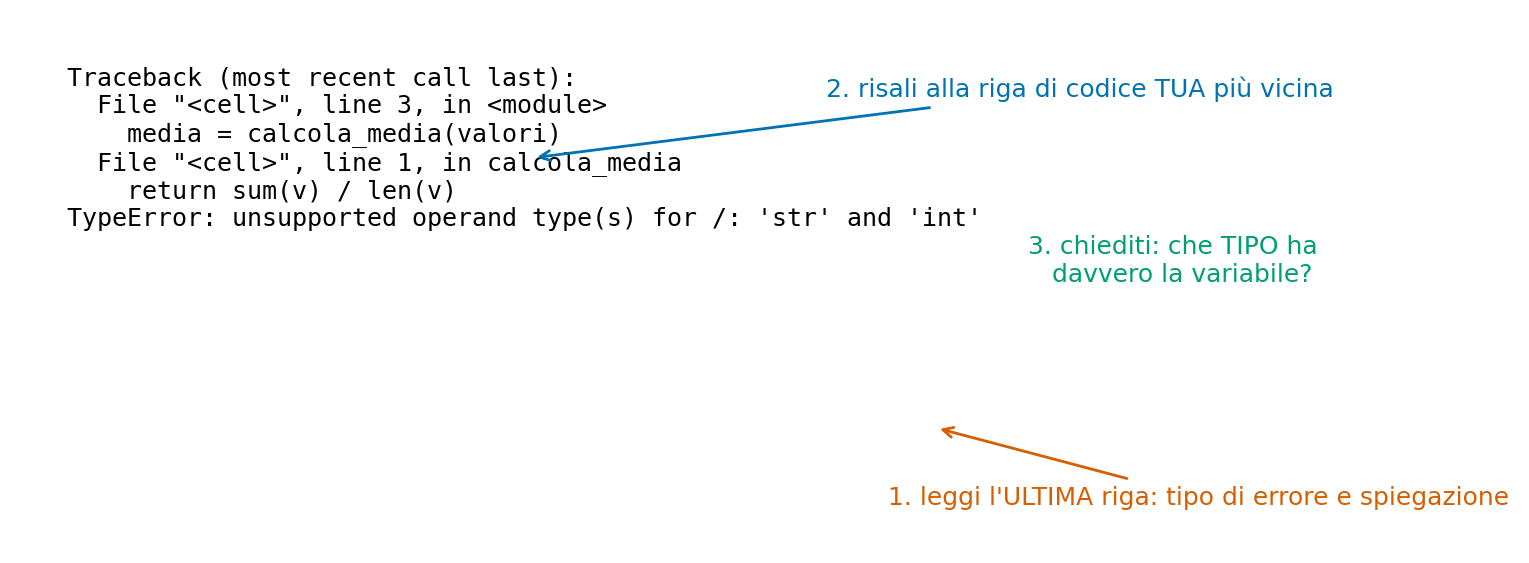

### I sei errori che vedrete più spesso

| Errore | Cosa dice | Causa tipica |
|---|---|---|
| `SyntaxError` | Python non riesce nemmeno a leggere la riga | `:` mancante, parentesi non chiusa, virgolette aperte |
| `IndentationError` | l'indentazione non torna | spazio in più o in meno, mescolare tab e spazi |
| `NameError: name 'x' is not defined` | quel nome non esiste | errore di battitura; cella non eseguita; kernel riavviato |
| `TypeError` | operazione fra tipi incompatibili | `"3" + 2`; una stringa dove serve un numero |
| `IndexError` / `KeyError` | indice o chiave inesistente | lista più corta del previsto; nome di colonna sbagliato |
| `FileNotFoundError` | il file non c'è dove lo cerca Python | percorso sbagliato, si lavora in un'altra cartella |

Guardate un errore vero: eseguite la cella qui sotto.

In [9]:
# Provocare un errore apposta è il modo migliore per imparare a leggerlo.
# Leggete la RIGA FINALE, poi risalite alla riga con la freccia.
valori = ["3.2", "4.1"]
print(valori[0] + 1)

TypeError: can only concatenate str (not "int") to str

Riga finale: `TypeError: can only concatenate str (not "int") to str`, cioè state sommando un
testo e un numero. La freccia indica la riga: `valori[0]` è la stringa `"3.2"`. Soluzione: `float(valori[0]) + 1`.

### Intercettare un errore previsto: `try` / `except`

A volte un errore è previsto (un file malformato in una cartella di cento) e non volete che
fermi tutto. `try` prova il blocco; se si verifica quell'errore, esegue `except` invece di
fermarsi. Usatelo solo per errori che sapete spiegare, e intercettate il tipo preciso: un
`except` generico nasconde anche i bug veri.

In [10]:
for testo in ["3.2", "4,1", "n.d."]:
    try:
        print(testo, "->", float(testo))
    except ValueError as errore:
        print(testo, "-> non è un numero:", errore)

3.2 -> 3.2
4,1 -> non è un numero: could not convert string to float: '4,1'
n.d. -> non è un numero: could not convert string to float: 'n.d.'


### Esercizio 2.2: caccia al bug

Cinque celle, cinque frammenti rotti. Eseguitele una alla volta, leggete il messaggio e
riparate. Prima leggete l'errore, poi guardate il codice: l'obiettivo è allenare il metodo.

In [11]:
# BUG 1
#> temperature = [21.5, 22.0, 22.7, 23.1]
#> for t in temperature
#>     print(t + 273.15)
# --- SOLUZIONE ---
temperature = [21.5, 22.0, 22.7, 23.1]
for t in temperature:
    print(t + 273.15)

294.65
295.15
295.84999999999997
296.25


In [12]:
# BUG 2
#> conc = "12.5"
#> massa = conc * 0.05
#> print(f"massa = {massa:.3f} µg")
# --- SOLUZIONE ---
conc = float("12.5")
massa = conc * 0.05
print(f"massa = {massa:.3f} µg")

massa = 0.625 µg


In [13]:
# BUG 3
#> misure = [2.1, 3.4, 5.0]
#> print(misure[3])
# --- SOLUZIONE ---
misure = [2.1, 3.4, 5.0]
print(misure[2])       # l'ultimo è l'indice 2 (o -1): si conta da zero

5.0


In [14]:
# BUG 4
#> def media_lista(valori):
#>     return sum(valori) / len(valori)
#> print(media_lsta([1, 2, 3]))
# --- SOLUZIONE ---
def media_lista(valori):
    return sum(valori) / len(valori)
print(media_lista([1, 2, 3]))

2.0


In [15]:
# BUG 5
#> metadati = {"campione": "S01", "conc": 5.0}
#> print(metadati["Campione"])
# --- SOLUZIONE ---
metadati = {"campione": "S01", "conc": 5.0}
print(metadati["campione"])   # le chiavi distinguono maiuscole e minuscole

S01


---
## 4. File e cartelle con `pathlib`

Un `Path` è un percorso, di un file o di una cartella. Si compone con `/` (proprio
l'operatore di divisione) e funziona allo stesso modo su Mac e Windows.

Ricordate: `FileNotFoundError` quasi sempre significa che state cercando **nel posto
sbagliato**, non che il file manchi. `Path.cwd()` vi dice dove si trova Python adesso.

In [16]:
print(Path.cwd())                          # cartella di lavoro corrente

cartella = DATI / "strumento"
print(cartella, cartella.exists())

file = cartella / "DPV_S01.txt"
print(file.name, file.suffix, file.stem)   # nome, estensione, nome senza estensione

/home/claude/corso_python_cnr/docente
../dati/strumento True
DPV_S01.txt .txt DPV_S01


In [17]:
# Elencare i file di una cartella che rispettano uno schema
lista_file = sorted(cartella.glob("DPV_S*.txt"))
print(len(lista_file), "file")
for f in lista_file[:4]:
    print("  ", f.name)

13 file
   DPV_S01.txt
   DPV_S02.txt
   DPV_S03.txt
   DPV_S04.txt


### Leggere un file di testo

`read_text()` restituisce tutto il contenuto come una stringa; `splitlines()` la spezza
in una lista di righe. Guardiamo com'è fatto un file dello strumento.

In [18]:
testo = file.read_text(encoding="utf-8")
righe = testo.splitlines()
print(len(righe), "righe. Le prime 12:")
for r in righe[:12]:
    print(repr(r))        # repr mostra anche i caratteri invisibili, come \t

170 righe. Le prime 12:
'# Strumento: PalmSens4 (DPV)'
'# Campione: S01'
'# Data: 12/03/2026'
'# Matrice: tampone'
'# Concentrazione nominale (uM): 0.5'
'# Scan rate (mV/s): 50'
'# Elettrodo: SPCE'
''
'E(V)\ti(uA)'
'-0.600\t0.8094'
'-0.595\t0.7698'
'-0.590\t0.8273'


> **E `with open`?** `read_text()` è un metodo degli oggetti `Path`: apre il file, legge tutto
> il contenuto in una stringa e lo chiude. È equivalente a:
>
> ```python
> with open(file, encoding="utf-8") as f:
>     testo = f.read()
> ```
>
> dove `with` garantisce che il file venga chiuso all'uscita dal blocco, anche se nel mezzo
> c'è un errore. `with open(...)` serve quando il file è troppo grande per leggerlo tutto
> insieme (`for riga in f:` lo legge una riga alla volta), quando si vuole aggiungere in fondo
> a un file esistente (`open(file, "a")`), o quando si scrive un pezzo alla volta dentro un
> ciclo. `write_text()`, che userete più avanti, invece **sovrascrive** il file.

Cosa c'è dentro, in parole semplici: ogni file è una curva x-y registrata da uno strumento
(un voltammogramma: corrente `i` in funzione del potenziale applicato `E`). La curva ha un
picco sopra una linea di base (il "fondo"), e l'altezza del picco cresce con la
concentrazione del campione. Non serve sapere altro: lo schema è lo stesso di uno spettro, di
un cromatogramma o di un segnale di sensore.

Struttura tipica di un file da strumento:
1. un header di metadati (qui righe che iniziano con `#`),
2. una riga vuota,
3. un'intestazione di colonna,
4. i dati, due numeri per riga separati da tabulazione (`\t`).

Per estrarre i dati serve saltare l'header, spezzare ogni riga sul separatore e convertire
in numero. Le stringhe hanno i metodi che servono:

In [19]:
r = "# Concentrazione nominale (uM): 0.5"
print(r.startswith("#"))
chiave, valore = r.split(":")          # spezza sui due punti
print(chiave.strip("# "), "->", float(valore))

r = "-0.600\t0.8094"
parti = r.split("\t")
print(parti, float(parti[0]), float(parti[1]))

True
Concentrazione nominale (uM) -> 0.5
['-0.600', '0.8094'] -0.6 0.8094


### Esercizio 2.3: parsing di un file di strumento (livello 2)

> *Facoltativo: si può saltare se si è in ritardo.* Chi lo salta trova la funzione già pronta
> prima dell'esercizio 2.4.

Scrivete una funzione `leggi_dpv(percorso)` che restituisce tre cose: un dizionario
di metadati (chiave → valore, come testo), la lista dei potenziali `E` e la lista delle
correnti `i`.

Regole: le righe che iniziano con `#` sono metadati (`chiave: valore`); le righe vuote e
quella `E(V)\ti(uA)` si saltano; il resto sono dati.

In [20]:
# ESERCIZIO 2.3 (livello 2)
def leggi_dpv(percorso):
    """Legge un file DPV: restituisce (metadati, E, i)."""
    metadati = {}
    E = []
    i = []
    # per ogni riga del file:
    #   se inizia con "#": spezza su ":" (solo alla prima occorrenza: split(":", 1)),
    #                      pulisci la chiave con strip("# ") e il valore con strip(), salva nel dizionario
    #   altrimenti se la riga è vuota o inizia con "E(": salta (continue)
    #   altrimenti: spezza su "\t", converti in float, aggiungi a E e a i
    # --- SOLUZIONE ---
    for riga in percorso.read_text(encoding="utf-8").splitlines():
        if riga.startswith("#"):
            chiave, valore = riga.split(":", 1)
            metadati[chiave.strip("# ")] = valore.strip()
        elif riga.strip() == "" or riga.startswith("E("):
            continue
        else:
            e, c = riga.split("\t")
            E.append(float(e))
            i.append(float(c))
    # --- FINE SOLUZIONE ---
    return metadati, E, i

meta, E, i = leggi_dpv(file)
print(meta)
if E:      # se la funzione non è ancora completa, E è vuota: niente da mostrare
    print(len(E), "punti; primo:", E[0], i[0], "; ultimo:", E[-1], i[-1])
    print("corrente massima:", max(i))
else:
    print("E è vuota: completate la funzione (o saltate l'esercizio: la versione pronta è più avanti)")

{'Strumento': 'PalmSens4 (DPV)', 'Campione': 'S01', 'Data': '12/03/2026', 'Matrice': 'tampone', 'Concentrazione nominale (uM)': '0.5', 'Scan rate (mV/s)': '50', 'Elettrodo': 'SPCE'}
161 punti; primo: -0.6 0.8094 ; ultimo: 0.2 1.0901
corrente massima: 1.3289


---
## 5. NumPy: gli array

Una lista Python può contenere di tutto, e per questo è lenta e scomoda per la matematica:
`[1, 2, 3] * 2` ripete la lista, non moltiplica. Un **array NumPy** contiene numeri
tutti dello stesso tipo (`dtype`) disposti in una griglia con una forma (`shape`), e
le operazioni si applicano a tutti gli elementi in una volta. Si chiama *vettorizzazione*:
è 10-100 volte più veloce di un ciclo `for`, e si legge meglio.

In [21]:
a = np.array([1.0, 2.0, 5.0, 10.0])
print(a * 2)                 # moltiplica ogni elemento
print(a + a)                 # elemento per elemento
print(np.sqrt(a))
print(a.dtype, a.shape, a.size)

[ 2.  4. 10. 20.]
[ 2.  4. 10. 20.]
[1.         1.41421356 2.23606798 3.16227766]
float64 (4,) 4


In [22]:
# Eseguite questa cella IN OGNI CASO: NumPy sa leggere da solo un file a colonne, basta dirgli
# quante righe di testa saltare. Le celle seguenti vogliono E e i come array NumPy (con le liste
# dell'esercizio 2.3, i.min() darebbe errore).
E, i = np.loadtxt(file, skiprows=9, unpack=True)
print(E.shape, i.dtype)

(161,) float64


### Il primo grafico: prima di tutto si guarda il dato

Prima di qualsiasi calcolo si guarda il dato. Un grafico rapido mostra subito
quello che una tabella nasconde: il picco c'è? il fondo è inclinato? c'è un punto impazzito?

La forma che useremo sempre: `fig, ax = plt.subplots()` crea un foglio (`fig`) con un
riquadro (`ax`), poi si disegna sull'`ax`. Il giorno 3 la porteremo a livello pubblicazione;
oggi basta questo.

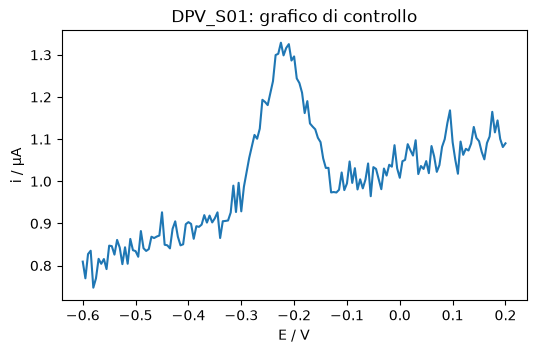

In [23]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(E, i)
ax.set_xlabel("E / V")
ax.set_ylabel("i / µA")
ax.set_title(f"{file.stem}: grafico di controllo")
plt.show()

Ecco il picco di cui parlavamo: una gobba attorno a -0.2 V, sopra un fondo. Tutto quello che
segue è un modo di descrivere questa curva con dei numeri. Cominciamo dal punto più alto.

In [24]:
# Le funzioni statistiche sono tutte lì
print(f"i: min {i.min():.3f}, max {i.max():.3f}, media {i.mean():.3f}, std {i.std(ddof=1):.3f}")
print("indice del massimo:", i.argmax(), "-> potenziale di picco:", E[i.argmax()], "V")

i: min 0.748, max 1.329, media 1.005, std 0.134
indice del massimo: 75 -> potenziale di picco: -0.225 V


### Creare array

`np.arange` (come `range`, ma con i decimali), `np.linspace` (n punti equispaziati),
`np.zeros` / `np.ones`.

In [25]:
print(np.arange(0, 1, 0.25))
print(np.linspace(0, 1, 5))
print(np.zeros(3), np.ones((2, 3)))

[0.   0.25 0.5  0.75]
[0.   0.25 0.5  0.75 1.  ]
[0. 0. 0.] [[1. 1. 1.]
 [1. 1. 1.]]


### Indicizzazione booleana: il filtro

Un confronto su un array produce un array di `True`/`False`, cioè una **maschera**. Usata come
indice, tiene solo i `True`. È il filtro di Excel, ma si possono combinare più condizioni:
`&` per "e", `|` per "o", `~` per "non", con le parentesi attorno a ogni confronto.

In [26]:
maschera = i > 1.1
print(maschera[70:80])
print("punti sopra 1.1 µA:", maschera.sum())      # True conta 1
print("potenziali corrispondenti:", E[maschera][:5], "...")

finestra = (E > -0.35) & (E < -0.10)              # solo attorno al picco
print(f"massimo nella finestra: {i[finestra].max():.3f} µA")

[ True  True  True  True  True  True  True  True  True  True]
punti sopra 1.1 µA: 34
potenziali corrispondenti: [-0.275 -0.27  -0.265 -0.26  -0.255] ...
massimo nella finestra: 1.329 µA


### NaN: il valore mancante

`np.nan` (*not a number*) rappresenta il dato mancante, e si propaga: la media di un
array con un NaN è NaN. Esistono le versioni `nanmean`, `nanstd`, … che lo ignorano, e
`np.isnan` per trovarlo. Domani pandas gestirà tutto questo in modo più comodo.

In [27]:
v = np.array([3.2, np.nan, 3.4, 3.1])
print(v.mean(), np.nanmean(v))
print(np.isnan(v), np.isnan(v).sum(), "mancanti")
print(v[~np.isnan(v)])              # tenere solo i validi

nan 3.233333333333333
[False  True False False] 1 mancanti
[3.2 3.4 3.1]


---
## 6. Dal picco alla tabella riassuntiva

### Altezza di picco corretta per la linea di base

L'altezza "vera" del picco è il massimo meno il fondo (la linea di base). Stimiamo il fondo
come la media della corrente nella zona lontana dal picco (E < -0.45 V): una maschera e una media.

In [28]:
fondo = i[E < -0.45].mean()
i_picco = i.max() - fondo
print(f"fondo = {fondo:.3f} µA, picco netto = {i_picco:.3f} µA")

fondo = 0.830 µA, picco netto = 0.499 µA


> Una semplificazione da conoscere: nel grafico di controllo il fondo non è piatto, **sale** da
> sinistra a destra. Usando la sola media a sinistra, sotto il picco sottraiamo un po' troppo
> poco: ogni picco netto risulta più alto del vero di circa 0.13 µA. È un errore costante, quindi
> pesa sui picchi piccoli (circa +30 % per S01) e quasi niente su quelli grandi; in una retta di
> taratura finisce nell'intercetta, non nella pendenza. Per oggi va bene così; il metodo corretto
> è stimare il fondo con una retta da entrambi i lati del picco e sottrarla (provatelo
> nell'estensione facoltativa 3 dell'esercizio 2.4; le regressioni vere e proprie: giorno 3).

### Esercizio 2.4: ciclo su una cartella e tabella riassuntiva (livello 2)

Qui si vede a cosa serve Python. A mano fareste: apri il file, leggi il massimo, copia in
Excel, ripeti dodici volte. Qui:

1. per ogni file `DPV_S*.txt` della cartella `DATI / "strumento"`, leggetelo con `leggi_dpv`;
2. calcolate il picco netto come nella cella qui sopra (massimo meno la media della corrente per E < -0.45 V);
3. raccogliete in una lista di righe: campione, matrice, concentrazione nominale (così come
   è scritta nel file), potenziale di picco e corrente di picco netta (questi due con 3 decimali:
   `f"{x:.3f}"`);
4. scrivete la tabella in un file `riassunto_dpv.csv` (una riga per campione, valori
   separati da virgola), nella cartella di lavoro corrente;
5. stampate la tabella a video.

Il file `DPV_S13_malformato.txt` va escluso. Lo schema `DPV_S??.txt`, con due `?`, lo esclude
automaticamente (`?` vuol dire un carattere qualsiasi).

Suggerimento per scrivere il CSV: costruite ogni riga come stringa con `",".join([...])` e
alla fine `Path("riassunto_dpv.csv").write_text("\n".join(righe_csv), encoding="utf-8")` (indicate sempre
la codifica: su Windows il default non è UTF-8).

In [29]:
# Chi ha saltato l'esercizio 2.3 esegua questa cella: definisce leggi_dpv già pronta.
# (Chi l'ha fatto può eseguirla lo stesso: la sostituisce con una versione equivalente.)
def leggi_dpv(percorso):
    """Legge un file DPV: restituisce (metadati, E, i)."""
    metadati, E, i = {}, [], []
    for riga in percorso.read_text(encoding="utf-8").splitlines():
        if riga.startswith("#"):
            chiave, valore = riga.split(":", 1)
            metadati[chiave.strip("# ")] = valore.strip()
        elif riga.strip() == "" or riga.startswith("E("):
            continue
        else:
            e, c = riga.split("\t")
            E.append(float(e))
            i.append(float(c))
    return metadati, E, i

In [30]:
# ESERCIZIO 2.4 (livello 2): sostituisci i ____
#> righe_csv = ["campione,matrice,conc_nominale_uM,E_picco_V,i_picco_uA"]    # l'intestazione
#> for f in sorted((DATI / "strumento").glob(____)):
#>     meta, E, i = leggi_dpv(f)
#>     E, i = np.array(E), np.array(i)
#>     fondo = i[E < ____].mean()
#>     k = i.argmax()                      # posizione del massimo
#>     riga = [meta["Campione"], meta["Matrice"], meta["Concentrazione nominale (uM)"],
#>             f"{E[k]:.3f}", f"{____:.3f}"]
#>     righe_csv.append(",".join(riga))
#>
#> Path("riassunto_dpv.csv").write_text("\n".join(righe_csv) + "\n", encoding="utf-8")
#> print("\n".join(righe_csv))
# --- SOLUZIONE ---
righe_csv = ["campione,matrice,conc_nominale_uM,E_picco_V,i_picco_uA"]
for f in sorted((DATI / "strumento").glob("DPV_S??.txt")):
    meta, E, i = leggi_dpv(f)
    E, i = np.array(E), np.array(i)
    fondo = i[E < -0.45].mean()
    k = i.argmax()
    riga = [meta["Campione"], meta["Matrice"], meta["Concentrazione nominale (uM)"],
            f"{E[k]:.3f}", f"{i[k] - fondo:.3f}"]
    righe_csv.append(",".join(riga))

Path("riassunto_dpv.csv").write_text("\n".join(righe_csv) + "\n", encoding="utf-8")
print("\n".join(righe_csv))

campione,matrice,conc_nominale_uM,E_picco_V,i_picco_uA
S01,tampone,0.5,-0.225,0.499
S02,tampone,1,-0.220,0.682
S03,tampone,2,-0.220,1.130
S04,tampone,5,-0.215,2.365
S05,tampone,10,-0.215,4.515
S06,tampone,20,-0.220,8.760
S07,tampone,50,-0.220,21.352
S08,tampone,100,-0.220,42.252
S09,estratto foglia,5,-0.225,2.400
S10,estratto foglia,10,-0.220,4.529
S11,estratto foglia,20,-0.225,8.648
S12,estratto foglia,50,-0.225,21.147


> *Estensione facoltativa 1*: includete anche `DPV_S13_malformato.txt`. Rendete `leggi_dpv`
> robusta: sostituite la virgola decimale con il punto (`riga.replace(",", ".")`) e saltate
> le righe di dati che non hanno esattamente due campi.
>
> *Estensione facoltativa 2*: fate un unico grafico con tutti i voltammogrammi in tampone
> sovrapposti, con una legenda che riporti la concentrazione (`ax.plot(E, i, label=...)`
> dentro il ciclo, poi `ax.legend()`).
>
> *Estensione facoltativa 3*: stimate il fondo con una retta invece che con una media. Calcolate il
> punto medio (E medio, i media) della zona a sinistra del picco (E < -0.45 V), chiamatelo `(x1, y1)`,
> e quello della zona a destra (E > 0 V), `(x2, y2)`. Il fondo sotto il picco è il valore della retta
> che passa per i due punti, calcolato al potenziale del picco: `fondo = y1 + (y2 - y1) / (x2 - x1) * (E[k] - x1)`.
> Il picco netto è `i[k] - fondo`. Controllo: per S01 dovreste ottenere 0.380 µA invece di 0.499, per
> S08 42.118 invece di 42.252.

#### Soluzioni delle estensioni (solo versione docente)

Usano nomi di variabili diversi dall'esercizio, così non toccano `riassunto_dpv.csv` né le
variabili usate più avanti.

In [31]:
# ESTENSIONE 1: includere anche il file malformato (virgola decimale)
def leggi_dpv_robusta(percorso):
    """Come leggi_dpv, ma accetta la virgola decimale e salta le righe di dati malformate."""
    metadati, E, i = {}, [], []
    for riga in percorso.read_text(encoding="utf-8").splitlines():
        if riga.startswith("#"):
            chiave, valore = riga.split(":", 1)
            metadati[chiave.strip("# ")] = valore.strip()
        elif riga.strip() == "" or riga.startswith("E("):
            continue
        else:
            campi = riga.replace(",", ".").split("\t")
            if len(campi) != 2:
                continue
            E.append(float(campi[0]))
            i.append(float(campi[1]))
    return metadati, E, i

for f in sorted((DATI / "strumento").glob("DPV_S*.txt")):        # S* invece di S??: entra anche S13
    meta_r, E_r, i_r = leggi_dpv_robusta(f)
    E_r, i_r = np.array(E_r), np.array(i_r)
    k = i_r.argmax()
    netto = i_r[k] - i_r[E_r < -0.45].mean()
    print(f"{f.name:24s} {meta_r['Campione']}  {meta_r['Concentrazione nominale (uM)']:>4s} µM  {netto:7.3f} µA")
# Attenzione: il file malformato dichiara "Campione: S03", quindi S03 compare due volte
# (è il gancio per i duplicati del giorno 2).

DPV_S01.txt              S01   0.5 µM    0.499 µA
DPV_S02.txt              S02     1 µM    0.682 µA
DPV_S03.txt              S03     2 µM    1.130 µA
DPV_S04.txt              S04     5 µM    2.365 µA
DPV_S05.txt              S05    10 µM    4.515 µA
DPV_S06.txt              S06    20 µM    8.760 µA
DPV_S07.txt              S07    50 µM   21.352 µA
DPV_S08.txt              S08   100 µM   42.252 µA
DPV_S09.txt              S09     5 µM    2.400 µA
DPV_S10.txt              S10    10 µM    4.529 µA
DPV_S11.txt              S11    20 µM    8.648 µA
DPV_S12.txt              S12    50 µM   21.147 µA
DPV_S13_malformato.txt   S03     2 µM    1.130 µA


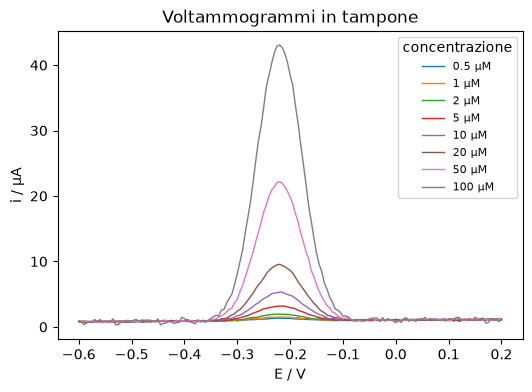

In [32]:
# ESTENSIONE 2: voltammogrammi in tampone sovrapposti, con legenda
fig, ax = plt.subplots(figsize=(6, 4))
for f in sorted((DATI / "strumento").glob("DPV_S??.txt")):
    meta_v, E_v, i_v = leggi_dpv(f)
    if meta_v["Matrice"] == "tampone":
        ax.plot(E_v, i_v, lw=1, label=f"{meta_v['Concentrazione nominale (uM)']} µM")
ax.set_xlabel("E / V")
ax.set_ylabel("i / µA")
ax.set_title("Voltammogrammi in tampone")
ax.legend(title="concentrazione", fontsize=8)
plt.show()

In [33]:
# ESTENSIONE 3: fondo stimato con una retta fra i due lati del picco
for f in sorted((DATI / "strumento").glob("DPV_S??.txt")):
    meta_f, E_f, i_f = leggi_dpv(f)
    E_f, i_f = np.array(E_f), np.array(i_f)
    sx, dx = E_f < -0.45, E_f > 0
    x1, y1 = E_f[sx].mean(), i_f[sx].mean()          # punto medio a sinistra
    x2, y2 = E_f[dx].mean(), i_f[dx].mean()          # punto medio a destra
    k = i_f.argmax()
    fondo_retta = y1 + (y2 - y1) / (x2 - x1) * (E_f[k] - x1)
    fondo_piatto = y1
    print(f"{meta_f['Campione']}: piatto {i_f[k] - fondo_piatto:7.3f}   retta {i_f[k] - fondo_retta:7.3f} µA")

S01: piatto   0.499   retta   0.380 µA
S02: piatto   0.682   retta   0.560 µA
S03: piatto   1.130   retta   1.004 µA
S04: piatto   2.365   retta   2.237 µA
S05: piatto   4.515   retta   4.382 µA
S06: piatto   8.760   retta   8.625 µA
S07: piatto  21.352   retta  21.223 µA
S08: piatto  42.252   retta  42.118 µA
S09: piatto   2.400   retta   2.271 µA
S10: piatto   4.529   retta   4.409 µA
S11: piatto   8.648   retta   8.535 µA
S12: piatto  21.147   retta  21.042 µA


### Un grafico di controllo sulla tabella prodotta

Non abbiamo ancora pandas: rileggiamo il CSV con NumPy. Un grafico del picco in funzione
della concentrazione risponde subito alla domanda "la risposta è lineare?".

('campione', 'matrice', 'conc_nominale_uM', 'E_picco_V', 'i_picco_uA')


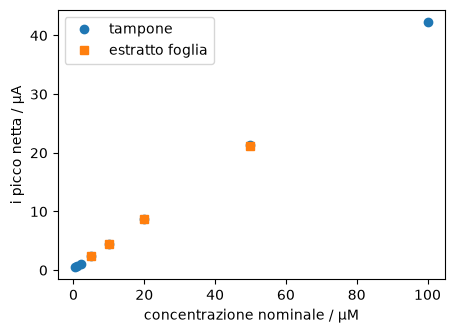

In [34]:
if not Path("riassunto_dpv.csv").exists():
    raise FileNotFoundError("Prima completate l'esercizio 2.4: questa cella legge il file che produce.")
tab = np.genfromtxt("riassunto_dpv.csv", delimiter=",", names=True, encoding="utf-8",
                    dtype=None)
print(tab.dtype.names)
tampone = tab["matrice"] == "tampone"

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(tab["conc_nominale_uM"][tampone], tab["i_picco_uA"][tampone], "o", label="tampone")
ax.plot(tab["conc_nominale_uM"][~tampone], tab["i_picco_uA"][~tampone], "s", label="estratto foglia")
ax.set_xlabel("concentrazione nominale / µM")
ax.set_ylabel("i picco netta / µA")
ax.legend()
plt.show()

---
## Riepilogo del giorno 1

- Una funzione dà un nome a un pezzo di lavoro e lo rende riusabile e verificabile.
- Un traceback si legge dal basso: tipo di errore, poi la riga indicata, poi la domanda
  "che tipo ha davvero questa variabile?".
- `pathlib.Path` per file e cartelle; `.glob()` per elencare; `.read_text()` per leggere.
- NumPy: array omogenei, operazioni vettorizzate, maschere booleane, `nan*`.
- `fig, ax = plt.subplots()` e poi `ax.plot(...)`: il grafico di controllo.

Domani: pandas. Il file `riassunto_dpv.csv` che avete appena scritto lo apriremo con una
riga sola, e il CSV "sporco" esportato dal laboratorio lo puliremo insieme.

---
*Materiale ispirato a Software Carpentry (CC-BY 4.0) e Aalto Scientific Computing,
"Python for Scientific Computing" (CC-BY 4.0).*